In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [2]:
df=pd.read_csv("ice_cream_sales.csv")
print(df.head())

         Date DayOfWeek  Month  Temperature  Rainfall  IceCreamsSold
0  2025-04-01   Tuesday  April         59.4      0.74             61
1  2025-04-03  Thursday  April         53.6      0.28             33
2  2025-04-06    Sunday  April         51.4      0.14             21
3  2025-04-07    Monday  April         50.8      0.06             23
4  2025-04-08   Tuesday  April         57.4      0.79             51


In [3]:
print("Dataset Shape:",df.shape)

Dataset Shape: (200, 6)


In [4]:
print("Dataset Information:")
df.info()
print("Statistical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           200 non-null    str    
 1   DayOfWeek      200 non-null    str    
 2   Month          200 non-null    str    
 3   Temperature    200 non-null    float64
 4   Rainfall       200 non-null    float64
 5   IceCreamsSold  200 non-null    int64  
dtypes: float64(2), int64(1), str(3)
memory usage: 13.9 KB
Statistical Summary:
       Temperature    Rainfall  IceCreamsSold
count   200.000000  200.000000     200.000000
mean     72.429500    0.283450     129.120000
std      11.602191    0.245561      58.234197
min      49.700000    0.000000      15.000000
25%      64.000000    0.110000      85.250000
50%      73.000000    0.205000     130.500000
75%      80.675000    0.387500     171.250000
max      98.300000    1.500000     256.000000


In [5]:
print(df.isna().sum())

Date             0
DayOfWeek        0
Month            0
Temperature      0
Rainfall         0
IceCreamsSold    0
dtype: int64


In [6]:
print(df.duplicated().sum())

0


In [7]:
df.columns

Index(['Date', 'DayOfWeek', 'Month', 'Temperature', 'Rainfall',
       'IceCreamsSold'],
      dtype='str')

In [8]:
print(df["DayOfWeek"].unique())
print(df["Month"].unique())

<ArrowStringArray>
['Tuesday', 'Thursday', 'Sunday', 'Monday', 'Wednesday', 'Friday', 'Saturday']
Length: 7, dtype: str
<ArrowStringArray>
['April', 'May', 'June', 'July', 'August', 'September', 'October']
Length: 7, dtype: str


In [9]:
df[["Temperature","Rainfall","IceCreamsSold"]].corr()

,Temperature,Rainfall,IceCreamsSold
Temperature,1.000000,0.024539,0.995541
Rainfall,0.024539,1.000000,-0.014479
IceCreamsSold,0.995541,-0.014479,1.000000


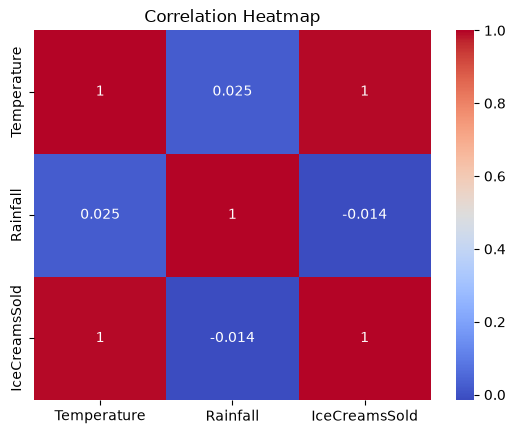

In [10]:
sns.heatmap(df[["Temperature","Rainfall","IceCreamsSold"]].corr(),annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

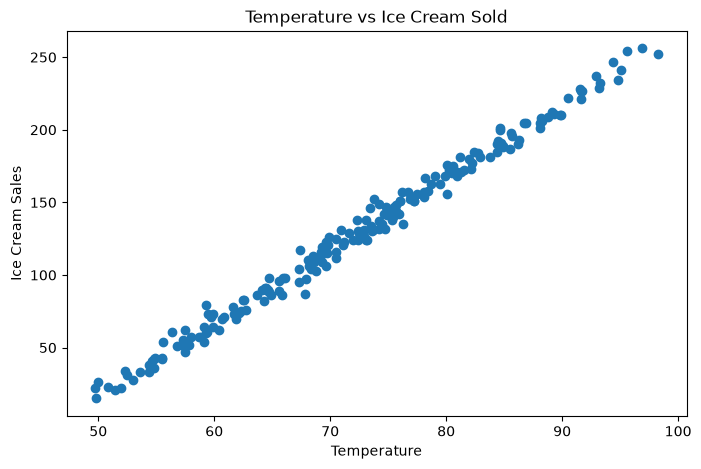

In [11]:
plt.figure(figsize=(8,5))
plt.scatter(df["Temperature"],df["IceCreamsSold"])
plt.title("Temperature vs Ice Cream Sold")
plt.xlabel("Temperature")
plt.ylabel("Ice Cream Sales")
plt.show()

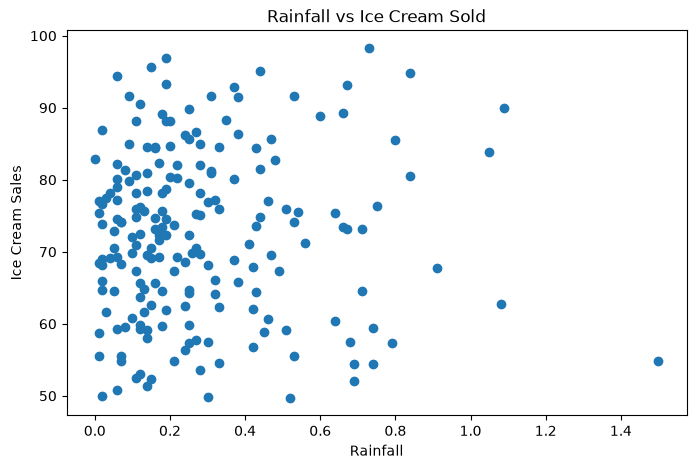

In [12]:
plt.figure(figsize=(8,5))
plt.scatter(df["Rainfall"],df["Temperature"])
plt.title("Rainfall vs Ice Cream Sold")
plt.xlabel("Rainfall")
plt.ylabel("Ice Cream Sales")
plt.show()

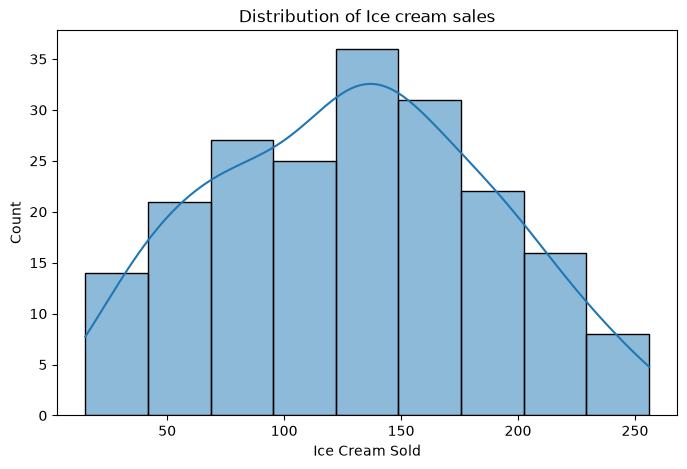

In [13]:
plt.figure(figsize=(8,5))
sns.histplot(df["IceCreamsSold"],kde=True)
plt.title("Distribution of Ice cream sales")
plt.xlabel("Ice Cream Sold")
plt.show()

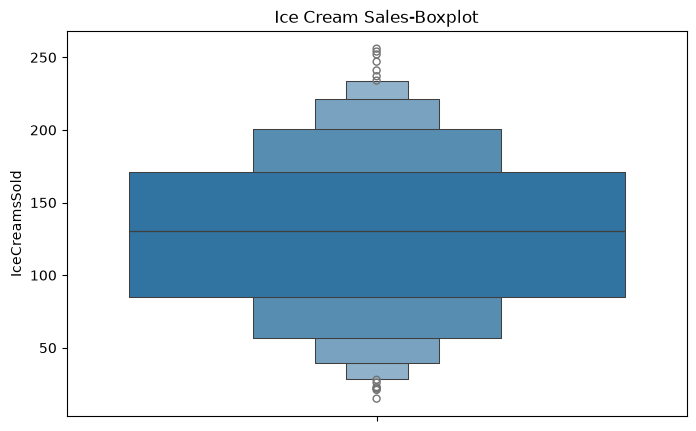

In [14]:
plt.figure(figsize=(8,5))
sns.boxenplot(df["IceCreamsSold"])
plt.title("Ice Cream Sales-Boxplot")
plt.show()

In [15]:
Q1=df["IceCreamsSold"].quantile(0.25)
Q3=df["IceCreamsSold"].quantile(0.75)

IQR= Q3-Q1
lower_bound=Q1 - 1.5 * IQR
upper_bound=Q3 + 1.5 * IQR

print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("lower bound:",lower_bound)
print("upper bound:",upper_bound)

Q1: 85.25
Q3: 171.25
IQR: 86.0
lower bound: -43.75
upper bound: 300.25


In [16]:
outliers=df[(df["IceCreamsSold"]<lower_bound) | (df["IceCreamsSold"]>upper_bound)]
print("Number of Outliers:",len(outliers))

Number of Outliers: 0


In [17]:
df["Date"]=pd.to_datetime(df["Date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           200 non-null    datetime64[us]
 1   DayOfWeek      200 non-null    str           
 2   Month          200 non-null    str           
 3   Temperature    200 non-null    float64       
 4   Rainfall       200 non-null    float64       
 5   IceCreamsSold  200 non-null    int64         
dtypes: datetime64[us](1), float64(2), int64(1), str(2)
memory usage: 12.0 KB


In [18]:
df["Day"]=df["Date"].dt.day
df["Year"]=df["Date"].dt.year
print(df.head())

        Date DayOfWeek  Month  Temperature  Rainfall  IceCreamsSold  Day  Year
0 2025-04-01   Tuesday  April         59.4      0.74             61    1  2025
1 2025-04-03  Thursday  April         53.6      0.28             33    3  2025
2 2025-04-06    Sunday  April         51.4      0.14             21    6  2025
3 2025-04-07    Monday  April         50.8      0.06             23    7  2025
4 2025-04-08   Tuesday  April         57.4      0.79             51    8  2025


In [19]:
X=df[["Temperature","Rainfall","DayOfWeek","Month"]]
y=df["IceCreamsSold"]

In [20]:
print("X shape:",X.shape)
print("y shape:",y.shape)

X shape: (200, 4)
y shape: (200,)


In [21]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [22]:
print("X train:",X_train.shape)
print("X test:",X_test.shape)
print("y train:",y_train.shape)
print("y test:",y_test.shape)

X train: (160, 4)
X test: (40, 4)
y train: (160,)
y test: (40,)


In [23]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         ["DayOfWeek", "Month"])
    ],
    remainder="passthrough"
)

In [24]:
X_train_encoded=preprocessor.fit_transform(X_train)

In [25]:
X_test_encoded=preprocessor.transform(X_test)

In [26]:
print("X_train_encoded shape:",X_train_encoded.shape)
print("X_test_encoded shape:",X_test_encoded.shape)

X_train_encoded shape: (160, 16)
X_test_encoded shape: (40, 16)


In [27]:
preprocessor.get_feature_names_out()

array(['cat__DayOfWeek_Friday', 'cat__DayOfWeek_Monday',
       'cat__DayOfWeek_Saturday', 'cat__DayOfWeek_Sunday',
       'cat__DayOfWeek_Thursday', 'cat__DayOfWeek_Tuesday',
       'cat__DayOfWeek_Wednesday', 'cat__Month_April',
       'cat__Month_August', 'cat__Month_July', 'cat__Month_June',
       'cat__Month_May', 'cat__Month_October', 'cat__Month_September',
       'remainder__Temperature', 'remainder__Rainfall'], dtype=object)

In [28]:
model=LinearRegression()
model.fit(X_train_encoded,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](16,)","[ 0.21,-0.53,-0.26,...,-0.96, 5.09,-8.75]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-237.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16


In [29]:
print("Model Coefficient:",model.coef_)
print("Model Intercept:",model.intercept_)

Model Coefficient: [ 0.2089286  -0.53292456 -0.2645434   0.91435669  0.85119834 -0.856501
 -0.32051465  1.9747674  -2.0794633  -0.35325814  0.63717871 -0.20100776
  0.98557453 -0.96379144  5.09325632 -8.75326837]
Model Intercept: -237.67483475280454


In [30]:
y_pred=model.predict(X_test_encoded)
print("Predicted values:",y_pred)

Predicted values: [210.52351596  66.19399666 128.6798692   90.51124041 170.84005819
 190.82408537 159.20910377  86.46214994  67.91197013  86.36539094
 155.90674593 115.68767984 107.77252014 128.86021897  28.11051144
 105.60922745 128.99285957 135.81053461 165.42336057 143.85661868
 135.09645168  48.92587988 112.94233939 224.06376437 128.48095721
 178.36737531 151.09297789 147.11526609 225.67967167 206.65204729
  38.97022436  47.07693647 180.10732513 132.50813036 133.07329415
 243.40350134 206.44196137 246.69921382 141.58301531 175.1256523 ]


In [31]:
comparision=pd.DataFrame({
    "Actual Values":y_test.values,
    "Predicted Values":y_pred
})
print(comparision.head(10))

   Actual Values  Predicted Values
0            210        210.523516
1             79         66.193997
2            124        128.679869
3             86         90.511240
4            181        170.840058
5            201        190.824085
6            156        159.209104
7             91         86.462150
8             70         67.911970
9             86         86.365391


In [35]:
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)

print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)
print("R2 Score:",r2)

MAE: 5.135784687086181
MSE: 40.099428699033545
RMSE: 6.33241097047827
R2 Score: 0.9862220688153788


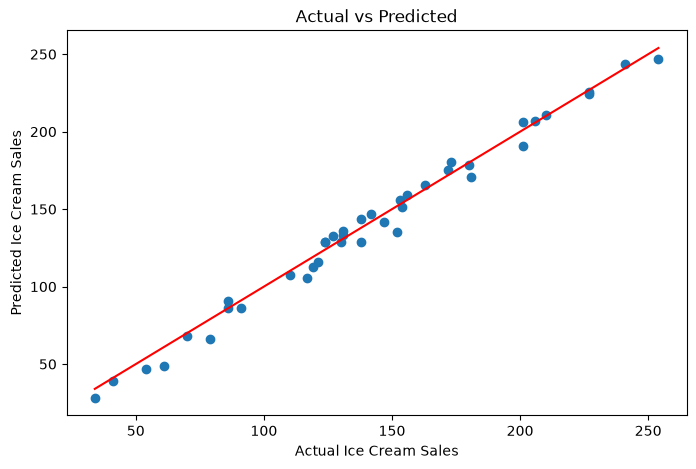

In [37]:
plt.figure(figsize=(8,5))
plt.scatter(y_test,y_pred)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],color="red")
plt.xlabel("Actual Ice Cream Sales")
plt.ylabel("Predicted Ice Cream Sales")
plt.title("Actual vs Predicted")
plt.show()

In [38]:
residuals=y_test-y_pred
print(residuals.head(10))

95     -0.523516
15     12.806003
30     -4.679869
158    -4.511240
128    10.159942
115    10.175915
69     -3.209104
170     4.537850
174     2.088030
45     -0.365391
Name: IceCreamsSold, dtype: float64


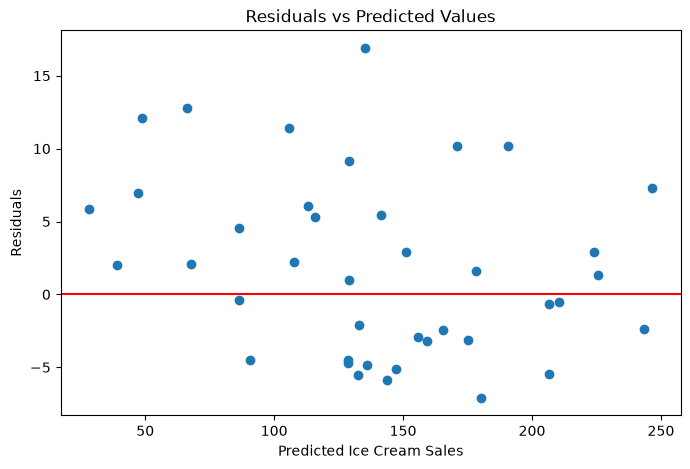

In [39]:
plt.figure(figsize=(8,5))
plt.scatter(y_pred,residuals)
plt.axhline(y=0, color="red")
plt.xlabel("Predicted Ice Cream Sales")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")

plt.show()

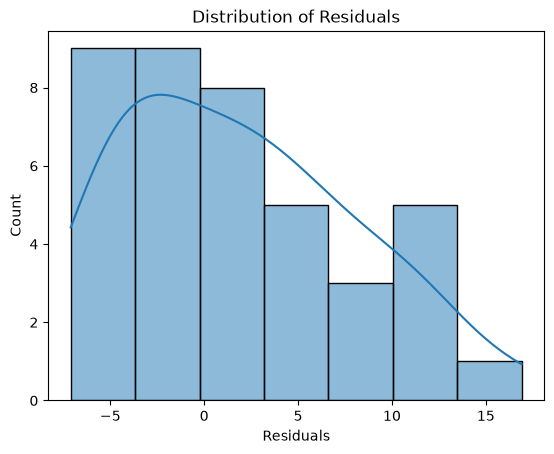

In [40]:
sns.histplot(residuals,kde=True)
plt.xlabel("Residuals")
plt.title("Distribution of Residuals")
plt.show()